# California housing: grouping houses with K-Means, then labeling new ones with a classifier

## Objectives

1. **Understand a new dataset:** the California Housing data from the 1990 census, one row per census block group.
2. **Model it with K-Means:** group the block groups into 6 clusters by location (`Latitude`, `Longitude`) and median income (`MedInc`).
3. **Analyze the results and train a supervised model** that learns those clusters, so new houses can be labeled quickly.

This is a common flow for unlabeled data: an **unsupervised** model creates the labels, and a **supervised** model learns to predict them.

## Setup

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

DATA_URL = "https://breathecode.herokuapp.com/asset/internal-link?id=439&path=housing.csv"
SEED = 42
FEATURES = ["Latitude", "Longitude", "MedInc"]

ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "housing.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "models"
for d in (RAW_PATH.parent, PROCESSED_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", "{:.2f}".format)

## Step 1: Load the dataset

The CSV is downloaded once and kept in `data/raw/`. Only three columns matter here: `Latitude`, `Longitude` and `MedInc` (median household income of the block group, in tens of thousands of dollars).

In [2]:
if not RAW_PATH.exists():
    pd.read_csv(DATA_URL).to_csv(RAW_PATH, index=False)

raw = pd.read_csv(RAW_PATH)
print(f"Full dataset: {raw.shape[0]:,} rows, {raw.shape[1]} columns")
print("Columns:", list(raw.columns))

df = raw[FEATURES].copy()
print(f"\nMissing values per column: {df.isna().sum().to_dict()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
df.describe()

Full dataset: 20,640 rows, 9 columns
Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Missing values per column: {'Latitude': 0, 'Longitude': 0, 'MedInc': 0}
Duplicate rows: 5


,Latitude,Longitude,MedInc
count,20640.00,20640.00,20640.00
mean,35.63,-119.57,3.87
std,2.14,2.00,1.90
min,32.54,-124.35,0.50
25%,33.93,-121.80,2.56
50%,34.26,-118.49,3.53
75%,37.71,-118.01,4.74
max,41.95,-114.31,15.00


Now split into **train (80%)** and **test (20%)**. K-Means does not need a test set to be evaluated, but keeping one aside lets us check later how the trained model labels houses it has never seen.

In [3]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=SEED)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
print(f"Train: {len(X_train):,} rows   Test: {len(X_test):,} rows")

Train: 16,512 rows   Test: 4,128 rows


## Step 2: Build a K-Means with 6 clusters

**One decision first: scaling.** K-Means groups points by distance. Latitude and longitude only vary by about 10 degrees across California, while income varies by about 15 units, so without scaling the columns would not count equally. A `StandardScaler` puts all three on the same scale first. Both steps are wrapped in one pipeline, so the same scaling is always applied to new data.

In [4]:
kmeans_model = make_pipeline(StandardScaler(), KMeans(n_clusters=6, n_init=10, random_state=SEED))
kmeans_model.fit(X_train)

X_train["cluster"] = pd.Categorical(kmeans_model.predict(X_train[FEATURES]))
print("Cluster column type:", X_train["cluster"].dtype)
print("\nHouses per cluster (train):")
print(X_train["cluster"].value_counts().sort_index().to_string())

Cluster column type: category

Houses per cluster (train):
cluster
0    1321
1    3380
2     453
3    3931
4    2239
5    5188


The cluster number is stored as a **category**, not a number: cluster 4 is not "more" than cluster 2, it is just a different group.

What does each cluster look like? The average location and income per cluster:

In [5]:
profile = X_train.groupby("cluster", observed=True)[FEATURES].mean()
profile["houses"] = X_train["cluster"].value_counts().sort_index()
profile.sort_values("MedInc", ascending=False)

,Latitude,Longitude,MedInc,houses
cluster,,,,
2,34.90,-119.24,10.44,453
4,37.70,-121.94,5.52,2239
1,33.87,-118.02,5.31,3380
3,38.35,-121.90,2.84,3931
5,33.82,-117.82,2.78,5188
0,36.08,-119.73,2.63,1321


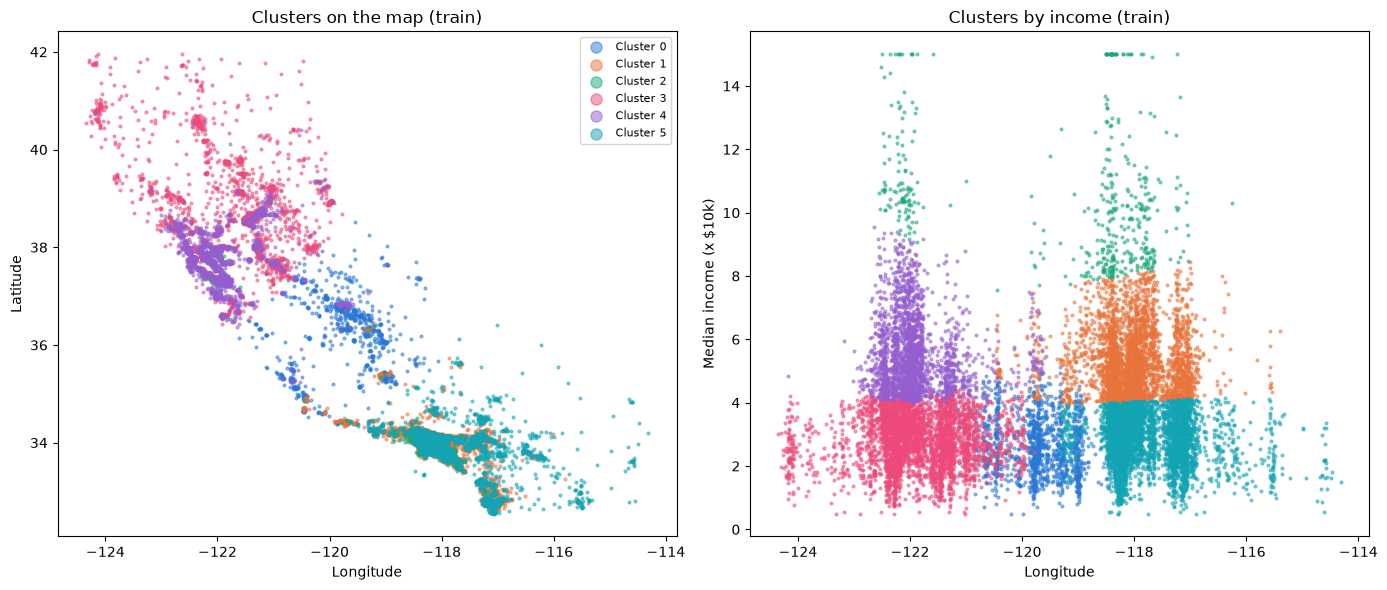

In [6]:
COLORS = ["#2a78d6", "#e8743b", "#19a979", "#ed4a7b", "#945ecf", "#13a4b4"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for k in sorted(X_train["cluster"].cat.categories):
    part = X_train[X_train["cluster"] == k]
    axes[0].scatter(part["Longitude"], part["Latitude"], s=4, alpha=0.5, color=COLORS[k], label=f"Cluster {k}")
    axes[1].scatter(part["Longitude"], part["MedInc"], s=4, alpha=0.5, color=COLORS[k], label=f"Cluster {k}")
axes[0].set(title="Clusters on the map (train)", xlabel="Longitude", ylabel="Latitude")
axes[1].set(title="Clusters by income (train)", xlabel="Longitude", ylabel="Median income (x $10k)")
axes[0].legend(markerscale=4, fontsize=8)
plt.tight_layout()
plt.show()

### What the clusters show

Reading the profile table and the two plots together, K-Means split California in two ways at once: **by region** and **by income**.

| Cluster | Where (average position) | Median income | Share of houses | In plain words |
|---|---|---|---|---|
| 5 | South (33.8°N, -117.8°) | 2.78 | 31% | Southern California, lower income |
| 1 | South (33.9°N, -118.0°) | 5.31 | 20% | Southern California, higher income |
| 3 | North (38.4°N, -121.9°) | 2.84 | 24% | Northern California and Sacramento area, lower income |
| 4 | North (37.7°N, -121.9°) | 5.52 | 14% | San Francisco Bay Area, higher income |
| 0 | Center (36.1°N, -119.7°) | 2.63 | 8% | Central Valley, the lowest incomes |
| 2 | Spread across the state | 10.44 | 3% | The wealthiest block groups, wherever they are |

- **Location drives most of the split.** The map shows three regions: the south (around Los Angeles and San Diego), the north (Bay Area and Sacramento) and the center.
- **Income splits the two big regions in half.** Both the south and the north have a lower-income cluster (about 2.8) and a higher-income cluster (about 5.3 to 5.5).
- **Very high income beats location.** Cluster 2 is small (3%) but its average income (10.4, about $104k in 1990) is so far from the rest that K-Means groups these block groups together even though they are in different parts of the state.
- `MedInc` is capped at 15 in this dataset, so the richest areas look slightly less extreme than they really are.

## Step 3: Predict clusters for the test set

The trained K-Means assigns each test house to the nearest cluster center. The test houses are drawn on top of the training map as black-edged crosses in their cluster's color. If the prediction works, each cross should sit inside the area of its own color.

Houses per cluster (test):
cluster
0     337
1     829
2     112
3     962
4     514
5    1374


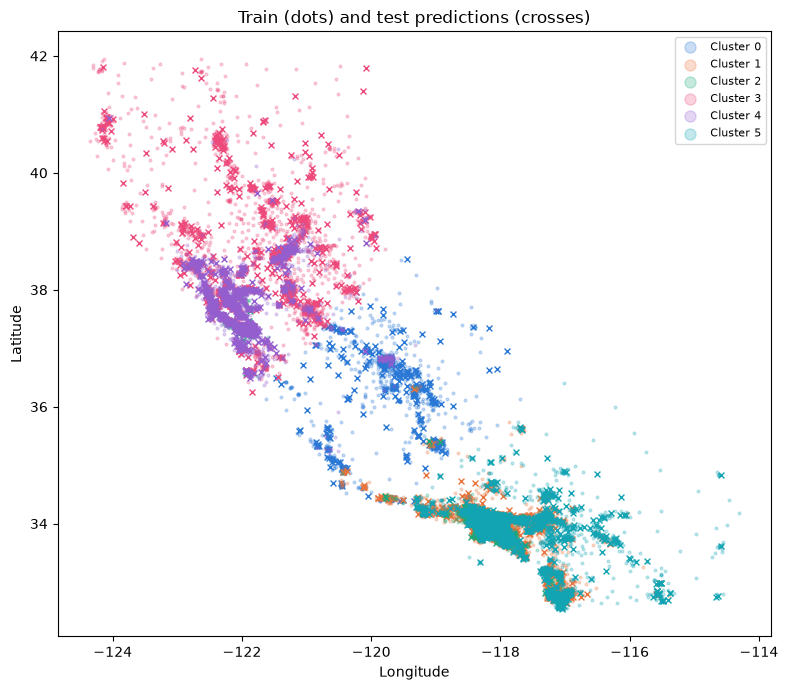

,train_%,test_%
cluster,,
0,8.00,8.16
1,20.47,20.08
2,2.74,2.71
3,23.81,23.30
4,13.56,12.45
5,31.42,33.28


In [7]:
X_test["cluster"] = pd.Categorical(kmeans_model.predict(X_test[FEATURES]), categories=X_train["cluster"].cat.categories)
print("Houses per cluster (test):")
print(X_test["cluster"].value_counts().sort_index().to_string())

fig, ax = plt.subplots(figsize=(8, 7))
for k in sorted(X_train["cluster"].cat.categories):
    part = X_train[X_train["cluster"] == k]
    ax.scatter(part["Longitude"], part["Latitude"], s=4, alpha=0.25, color=COLORS[k], label=f"Cluster {k}")
    test_part = X_test[X_test["cluster"] == k]
    ax.scatter(test_part["Longitude"], test_part["Latitude"], s=18, marker="x", color=COLORS[k], linewidths=1)
ax.set(title="Train (dots) and test predictions (crosses)", xlabel="Longitude", ylabel="Latitude")
ax.legend(markerscale=4, fontsize=8)
plt.tight_layout()
plt.show()

share = pd.DataFrame({
    "train_%": X_train["cluster"].value_counts(normalize=True).sort_index() * 100,
    "test_%": X_test["cluster"].value_counts(normalize=True).sort_index() * 100,
})
share

## Step 4: Train a supervised classifier on the clusters

Now the cluster numbers are treated as labels, and a classifier learns to predict them from the same three columns. Three candidates are compared:
- **Logistic regression:** simple and fast, but draws straight boundaries between classes.
- **Decision tree:** splits the data with simple rules ("latitude above 37.5", "income below 3.2"), which suits clusters that are separated by thresholds.
- **Random forest:** many decision trees voting together; usually more stable than a single tree.

Each is trained on the train set and scored on the test set.

In [8]:
y_train = X_train["cluster"].astype(int)
y_test = X_test["cluster"].astype(int)

candidates = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Decision tree": DecisionTreeClassifier(random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}
scores = {}
for name, model in candidates.items():
    model.fit(X_train[FEATURES], y_train)
    scores[name] = {
        "train_accuracy": accuracy_score(y_train, model.predict(X_train[FEATURES])),
        "test_accuracy": accuracy_score(y_test, model.predict(X_test[FEATURES])),
    }
scores = pd.DataFrame(scores).T.sort_values("test_accuracy", ascending=False)
scores.round(3)

,train_accuracy,test_accuracy
Random forest,1.00,0.99
Decision tree,1.00,0.99
Logistic regression,0.99,0.99


The best model on the test set is examined in detail:

In [9]:
best_name = scores.index[0]
classifier = candidates[best_name]
pred = classifier.predict(X_test[FEATURES])

print(f"Best model: {best_name}  (test accuracy {accuracy_score(y_test, pred):.3f})\n")
print(classification_report(y_test, pred, digits=3))
print("Confusion matrix (rows = true cluster, columns = predicted):")
print(confusion_matrix(y_test, pred))

Best model: Random forest  (test accuracy 0.995)

              precision    recall  f1-score   support

           0      0.994     0.985     0.990       337
           1      0.995     0.996     0.996       829
           2      1.000     0.982     0.991       112
           3      0.995     0.994     0.994       962
           4      0.988     0.996     0.992       514
           5      0.999     0.999     0.999      1374

    accuracy                          0.995      4128
   macro avg      0.995     0.992     0.994      4128
weighted avg      0.995     0.995     0.995      4128

Confusion matrix (rows = true cluster, columns = predicted):
[[ 332    1    0    3    1    0]
 [   1  826    0    0    0    2]
 [   0    2  110    0    0    0]
 [   1    0    0  956    5    0]
 [   0    0    0    2  512    0]
 [   0    1    0    0    0 1373]]


## Step 5: Save the models

Both models go in `models/`. They are small, so they are committed with the code. The train and test sets with their cluster labels are saved in `data/processed/`.

In [10]:
joblib.dump(kmeans_model, MODEL_DIR / "kmeans_6_clusters.pkl")
joblib.dump(classifier, MODEL_DIR / "cluster_classifier.pkl")
X_train.to_csv(PROCESSED_DIR / "housing_train_clusters.csv", index=False)
X_test.to_csv(PROCESSED_DIR / "housing_test_clusters.csv", index=False)

for p in sorted(MODEL_DIR.glob("*.pkl")):
    print(f"Saved {p.relative_to(ROOT)} ({p.stat().st_size / 1e6:.2f} MB)")

Saved models/cluster_classifier.pkl (12.15 MB)
Saved models/kmeans_6_clusters.pkl (0.07 MB)


## Conclusions

**K-Means produced 6 sensible groups.** After scaling, location and income counted equally, and the clusters read like a real description of California in 1990: lower- and higher-income groups in the south and in the north, a lower-income Central Valley group, and a small statewide group of very wealthy areas.

**The model works on new data.** On the test map, every test house lands inside the area of its own color, and each cluster's share is almost the same in train and test (for example 31.4% vs 33.3% for cluster 5, 2.7% vs 2.7% for cluster 2). The clusters are stable, not an accident of the training rows.

**The supervised model learns the clusters almost perfectly.** The random forest labels **99.5%** of the test houses correctly, and only 19 of 4,128 are wrong. The mistakes sit on the borders between neighboring clusters (for example between clusters 3 and 4, both in the north). The decision tree and the logistic regression also score about 99%.

**Why such a high score is expected here.** The labels were created by K-Means from these same three columns, using clear distance rules. Each cluster is a region of the (scaled) space with straight-line borders, so a classifier only has to rediscover those borders. That is also why the simple logistic regression does almost as well as the random forest. A score this high would be suspicious with real-world labels; here it means the labels are consistent.

**Which model to keep.** The random forest has the best score, but its file is about 12 MB. The logistic regression is almost as accurate and much smaller and faster, so for a production service it would be a reasonable choice too.

**Limits and next steps.**
- The number of clusters (6) was given. An elbow plot or silhouette score would show whether another number fits the data better.
- Only 3 columns were used. Adding house age, rooms or house value could produce more useful groups for pricing.
- The data is from 1990, so the income levels and the map are very different today.